In [5]:
import numpy as np
import matplotlib.pyplot as plt
from bandit import BanditLinear, BanditCongestion
import torch
from multi_level_rl import Population
from utils import get_pop_vector

import matplotlib.gridspec as gridspec

plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

plt.rcParams["text.latex.preamble"] = r"\usepackage{lmodern} \usepackage{amsmath}"
# Options
params = {
    "text.usetex": True,
    "font.size": 15,
    "font.family": "lmodern",
    #   'text.latex.unicode': True,
}
plt.rcParams.update(params)


def plot_mean_band(probs, q=(0.1, 0.9), ax=None):
    """Plot the population mean of probs (iterations x agents) with a quantile band."""
    ax = ax or plt.gca()
    t = np.arange(probs.shape[0])
    lo, hi = np.quantile(probs, q, axis=1)
    (line,) = ax.plot(t, probs.mean(axis=1), linewidth=1.5, label="mean")
    ax.fill_between(
        t,
        lo,
        hi,
        color=line.get_color(),
        alpha=0.3,
        linewidth=0,
        label=rf"{int(q[0] * 100)}--{int(q[1] * 100)}\% quantile",
    )
    ax.set_ylim(-0.02, 1.02)
    ax.legend()
    return ax

proportion of optimal policies: tensor(0.2110)


Text(0, 0.5, 'Probability of Optimal Policy')

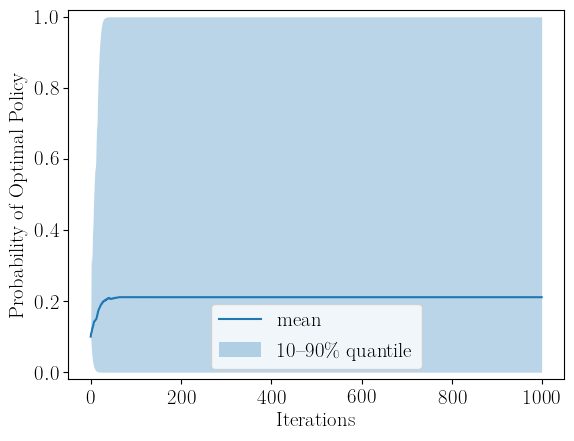

In [6]:
Bandit = BanditLinear(n_action=10, name="evenly spaced")
RL_population = Population(size=1000, arms=Bandit.return_no_actions())

num_samples = 1
iterations = 1000
alpha = 0.4
optimal_policies_percentage = np.zeros((iterations, RL_population.size))
optimal_policy_index = Bandit.optimal_action()

for i in range(iterations):
    optimal_policies_percentage[i, :] = RL_population.policies[
        :, optimal_policy_index
    ].numpy()
    # print(RL_population.policies)
    sampled_arms = RL_population.sample(num_samples=num_samples)

    rewards = Bandit.pull(sampled_arms)
    RL_population.update_policy_rl(sampled_arms, rewards, alpha, is_cl=True)


plot_mean_band(optimal_policies_percentage)

print(
    "proportion of optimal policies:",
    RL_population.proportion_of_optimal_policy(optimal_policy_index),
)

plt.xlabel("Iterations")
plt.ylabel("Probability of Optimal Policy")


# per agent update

proportion of optimal policies: tensor(0.9030)


Text(0, 0.5, 'Probability of Optimal Policy')

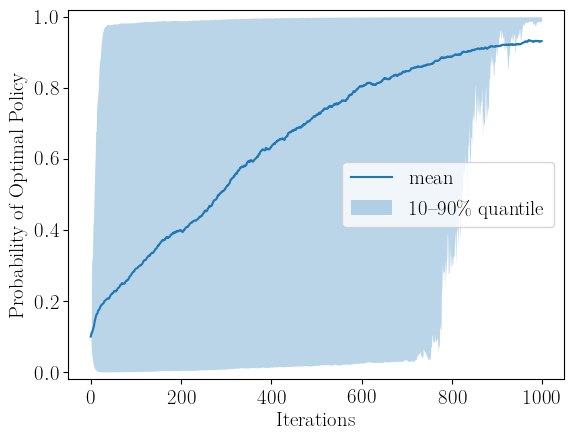

In [7]:
Bandit = BanditLinear(n_action=10, name="evenly spaced")
RL_population = Population(size=1000, arms=Bandit.return_no_actions())

num_samples = 1
iterations = 1000
alpha = 0.4
beta = 0.01
optimal_policies_percentage = np.zeros((iterations, RL_population.size))
optimal_policy_index = Bandit.optimal_action()

for i in range(iterations):
    optimal_policies_percentage[i, :] = RL_population.policies[
        :, optimal_policy_index
    ].numpy()
    # print(RL_population.policies)
    sampled_arms = RL_population.sample(num_samples=num_samples)

    rewards = Bandit.pull(sampled_arms)
    RL_population.update_policy_hybrid(sampled_arms, rewards, alpha, beta)


print(
    "proportion of optimal policies:",
    RL_population.proportion_of_optimal_policy(optimal_policy_index),
)


plot_mean_band(optimal_policies_percentage)
plt.xlabel("Iterations")
# plt.legend()
plt.ylabel("Probability of Optimal Policy")

proportion of optimal policies: tensor(0.)


Text(0, 0.5, 'Probability of Optimal Policy')

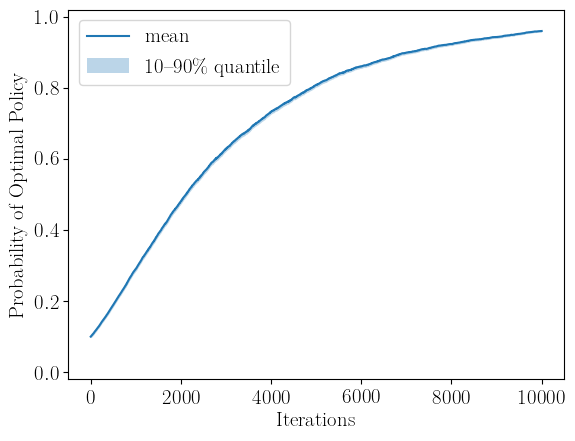

In [8]:
Bandit = BanditLinear(n_action=10, name="evenly spaced")
RL_population = Population(size=1000, arms=Bandit.return_no_actions())

num_samples = 1
iterations = 10000
alpha = 0.01
beta = 0.5
optimal_policies_percentage = np.zeros((iterations, RL_population.size))
optimal_policy_index = Bandit.optimal_action()

for i in range(iterations):
    optimal_policies_percentage[i, :] = RL_population.policies[
        :, optimal_policy_index
    ].numpy()
    # print(RL_population.policies)
    sampled_arms = RL_population.sample(num_samples=num_samples)

    rewards = Bandit.pull(sampled_arms)
    RL_population.update_policy_hybrid(sampled_arms, rewards, alpha, beta)


print(
    "proportion of optimal policies:",
    RL_population.proportion_of_optimal_policy(optimal_policy_index),
)


plot_mean_band(optimal_policies_percentage)
plt.xlabel("Iterations")
# plt.legend()
plt.ylabel("Probability of Optimal Policy")

Text(0, 0.5, 'Probability of Optimal Policy')

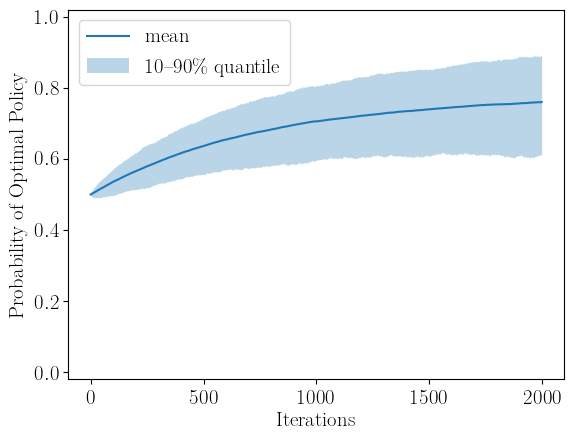

In [10]:
congestion_factors = [0.1, 0.4]
q_star = [0.7, 0.7]

banditcongestion = BanditCongestion(
    congestion_factors=congestion_factors, q_star=q_star, gap=0.1
)
RL_population = Population(size=1000, arms=banditcongestion.return_no_actions())

num_samples = 1
steps = 2000
alpha = 0.01
beta = 0.0

optimal_policies_percentage = np.zeros((steps, RL_population.size))
optimal_policy_index = 0

for i in range(steps):
    optimal_policies_percentage[i, :] = RL_population.policies[
        :, optimal_policy_index
    ].numpy()
    # print(RL_population.policies)
    sampled_arms = RL_population.sample(num_samples=num_samples)
    # print(sampled_arms)
    pop_vec = get_pop_vector(
        pop_types=sampled_arms, n_types=banditcongestion.return_no_actions()
    )
    rewards = banditcongestion.pull(sampled_arms, pop_vec)
    RL_population.update_policy_hybrid(sampled_arms, rewards, alpha, beta)

plot_mean_band(optimal_policies_percentage)
plt.xlabel("Iterations")
# plt.legend()
plt.ylabel("Probability of Optimal Policy")

In [ ]:
banditgames = 

In [24]:
# Create a mask for the sampled arms

Bandit = BanditLinear(n_action=2, name="evenly spaced")
RL_population = Population(size=3, arms=Bandit.return_no_actions())


alpha = 0.2
beta = 0.3
num_samples = 4

sampled_arms = RL_population.sample(num_samples=num_samples)
rewards = Bandit.pull(sampled_arms)

RL_population.policies = torch.tensor([[0.5, 0.5], [0.7, 0.3], [0.2, 0.8]])

sampled_arms_rows, sampled_arms_cols = torch_indices(sampled_arms.shape)
mask = torch.zeros((RL_population.size, sampled_arms.shape[1], RL_population.arms))
mask[sampled_arms_rows, sampled_arms_cols, sampled_arms] = 1
# calculate RL update
rep_policies = np.repeat(
    RL_population.policies[:, np.newaxis, :], sampled_arms.shape[1], axis=1
)

Rl_change = torch.einsum("ibj,ib-> ibj", mask - rep_policies, rewards).mean(axis=1)

# print("Sampled arms:", sampled_arms)
# print("Rewards:", rewards)
# print("mask:", mask)
# print("mask - rep_policies:", mask - rep_policies)
# print("change:", torch.einsum("ibj,ib-> ibj", mask - rep_policies, rewards))
# print("RL change:", Rl_change)


# calculate imitation update
imitating_partners = torch.multinomial(RL_population.imitation_matrix, 1).squeeze(1)
avg_rewards = rewards.mean(dim=1)
partner_rewards = avg_rewards[imitating_partners]

imitating_probabilities = torch.rand(RL_population.size)


imitation_change = torch.zeros_like(RL_population.policies)
imitation_mask = torch.where(imitating_probabilities < partner_rewards, True, False)

# print("imitation_mask:", imitation_mask)

# imitation_change = torch.zeros_like(RL_population.policies)
imitation_change[imitation_mask] = RL_population.policies[
    imitating_partners[imitation_mask]
]

print("imitation_matrix:", RL_population.imitation_matrix)
print("Imitating partners:", imitating_partners)
print("rewards:", rewards)
print("partner_rewards:", partner_rewards)
print("imitation_mask:", imitation_mask)
print("imitating_probabilities:", imitating_probabilities)
print("imitation_change:", imitation_change)


RL_population.policies += alpha * Rl_change + beta * imitation_change

imitation_matrix: tensor([[0.0000, 0.5000, 0.5000],
        [0.5000, 0.0000, 0.5000],
        [0.5000, 0.5000, 0.0000]])
Imitating partners: tensor([1, 2, 0])
rewards: tensor([[0.4880, 0.4363, 0.4147, 0.3990],
        [0.4693, 0.3643, 0.7943, 0.6366],
        [0.6010, 0.4901, 0.7362, 0.4104]])
partner_rewards: tensor([0.5661, 0.5594, 0.4345])
imitation_mask: tensor([ True, False,  True])
imitating_probabilities: tensor([0.0927, 0.9071, 0.1019])
imitation_change: tensor([[0.7000, 0.3000],
        [0.0000, 0.0000],
        [0.5000, 0.5000]])


In [21]:
torch.eye(RL_population.size)

tensor([[1., 0., 0.],
        [0., 1., 0.],
        [0., 0., 1.]])